# RFM segmentation and churn

Reads `retail_clean` from PostgreSQL, scores every customer on Recency, Frequency and Monetary value, assigns one of six segments using the rule table in `docs/BRD.md`, and flags churn (no purchase in the trailing 90 days).

Writes these tables back to Postgres:
- `customer_rfm`: one row per customer;
- `segment_rules`: the rule table;
- `analysis_ready`: transactions plus customer RFM columns, used by Power BI.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from matplotlib.ticker import FuncFormatter
from sqlalchemy import create_engine, text

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
load_dotenv(ROOT / ".env")
engine = create_engine(
    f"postgresql+psycopg2://{os.environ['PGUSER']}:{os.environ['PGPASSWORD']}"
    f"@{os.environ['PGHOST']}:{os.environ['PGPORT']}/{os.environ['PGDATABASE']}"
)
FIG_DIR = ROOT / "notebooks" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

## Chart style
Neutral base with one accent. Segment colours carry meaning: teal = healthy, slate = new, amber = needs a nudge, orange-red = at risk, grey = lost.

In [2]:
INK, MUTED, GRID, PAPER = "#1F2328", "#6B7280", "#E5E7EB", "#FFFFFF"
ACCENT, RISK = "#0F766E", "#C2410C"
SEGMENT_ORDER = ["Champions", "Loyal", "New", "Needs Attention", "At Risk", "Lost"]
SEGMENT_COLOURS = {
    "Champions": "#0F766E", "Loyal": "#5EA89E", "New": "#5B7C99",
    "Needs Attention": "#C9962B", "At Risk": "#C2410C", "Lost": "#868C96",
}
plt.rcParams.update({
    "font.family": ["Lato", "DejaVu Sans"], "font.size": 10,
    "text.color": INK, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.grid": False, "grid.color": GRID, "grid.linewidth": 0.8,
    "figure.facecolor": PAPER, "axes.facecolor": PAPER, "savefig.dpi": 160, "savefig.bbox": "tight",
})
gbp = FuncFormatter(lambda v, _: f"£{v/1e6:.1f}m" if abs(v) >= 1e6 else f"£{v/1e3:.0f}k")

## 1. Load cleaned transactions

In [3]:
tx = pd.read_sql(
    "SELECT invoice, invoice_date, customer_id, country, revenue FROM retail_clean",
    engine, parse_dates=["invoice_date"],
)
tx["revenue"] = tx["revenue"].astype(float)
print(f"rows: {len(tx):,}  customers: {tx.customer_id.nunique():,}  invoices: {tx.invoice.nunique():,}")
print(f"revenue: £{tx.revenue.sum():,.2f}")
print(f"dates: {tx.invoice_date.min()} to {tx.invoice_date.max()}")

rows: 779,425  customers: 5,878  invoices: 36,969
revenue: £17,374,804.27
dates: 2009-12-01 07:45:00 to 2011-12-09 12:50:00


## 2. Recency, Frequency, Monetary
- **Reference date:** the day after the last invoice date.
- **Recency:** whole days from the customer's last purchase date to the reference date, so a purchase on the last day gives Recency = 1.
- **Primary country:** a customer who bought under several countries is assigned the one with the most revenue.

In [4]:
reference_date = tx.invoice_date.max().normalize() + pd.Timedelta(days=1)
print("reference date:", reference_date.date())

rfm = tx.groupby("customer_id").agg(
    first_purchase=("invoice_date", "min"),
    last_purchase=("invoice_date", "max"),
    frequency=("invoice", "nunique"),
    monetary=("revenue", "sum"),
)
rfm["recency_days"] = (reference_date - rfm.last_purchase.dt.normalize()).dt.days

country_rev = tx.groupby(["customer_id", "country"]).revenue.sum().reset_index()
primary = (country_rev.sort_values(["customer_id", "revenue", "country"], ascending=[True, False, True])
           .drop_duplicates("customer_id").set_index("customer_id").country)
rfm["country"] = primary
print(f"customers: {len(rfm):,}; bought under >1 country: {(tx.groupby('customer_id').country.nunique() > 1).sum()}")
rfm[["recency_days", "frequency", "monetary"]].describe().round(2)

reference date: 2011-12-10
customers: 5,878; bought under >1 country: 13


,recency_days,frequency,monetary
count,5878.00,5878.00,5878.00
mean,201.87,6.29,2955.90
std,209.35,13.01,14440.85
min,1.00,1.00,2.95
25%,26.00,1.00,342.28
50%,96.00,3.00,867.74
75%,380.00,7.00,2248.30
max,739.00,398.00,580987.04


## 3. Quintile scores (1–5)
- `pd.qcut` into five equal-sized groups.
- Recency labels are reversed, so the most recent quintile scores 5.
- Frequency is ranked with `method='first'` before `qcut`. Many customers share the same small invoice count (e.g. 1), and without ranking the bin edges would collide.

In [5]:
rfm["r_score"] = pd.qcut(rfm.recency_days, 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["f_score"] = pd.qcut(rfm.frequency.rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["m_score"] = pd.qcut(rfm.monetary, 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["rfm_score"] = rfm.r_score.astype(str) + rfm.f_score.astype(str) + rfm.m_score.astype(str)

bounds = pd.concat({
    "recency_days": rfm.groupby("r_score").recency_days.agg(["min", "max", "size"]),
    "frequency": rfm.groupby("f_score").frequency.agg(["min", "max", "size"]),
    "monetary": rfm.groupby("m_score").monetary.agg(["min", "max", "size"]).round(2),
})
bounds.index.names = ["metric", "score"]
bounds

min        max  size
metric       score                          
recency_days 1       412.00     739.00  1168
             2       191.00     411.00  1175
             3        60.00     190.00  1180
             4        22.00      59.00  1140
             5         1.00      20.00  1215
frequency    1         1.00       1.00  1176
             2         1.00       2.00  1175
             3         2.00       4.00  1176
             4         4.00       8.00  1175
             5         8.00     398.00  1176
monetary     1         2.95     285.56  1176
             2       285.60     608.86  1175
             3       609.30    1220.90  1176
             4      1220.91    2909.86  1175
             5      2910.23  580987.04  1176

## 4. Segments from the rule table
Rules are evaluated top-down and the first match wins. Together they cover all 25 R×F cells. This is the same table as in `docs/BRD.md`.

In [6]:
segment_rules = pd.DataFrame([
    # order, segment,          R min, R max, F min, F max, meaning
    (1, "Champions",        4, 5, 4, 5, "Bought recently and buy often"),
    (2, "Loyal",            3, 5, 3, 5, "Regular buyers, not top on both recency and frequency"),
    (3, "New",              4, 5, 1, 2, "Bought recently, few orders so far"),
    (4, "Needs Attention",  3, 3, 1, 2, "Middling recency, low frequency"),
    (5, "At Risk",          1, 2, 3, 5, "Used to buy often, now gone quiet"),
    (6, "Lost",             1, 2, 1, 2, "Last bought long ago, few orders"),
], columns=["segment_order", "segment", "r_min", "r_max", "f_min", "f_max", "meaning"])


def assign_segment(r: int, f: int) -> str:
    for rule in segment_rules.itertuples():
        if rule.r_min <= r <= rule.r_max and rule.f_min <= f <= rule.f_max:
            return rule.segment
    raise ValueError(f"no rule for R={r}, F={f}")


# Every R×F cell must map to exactly one segment (first match).
grid = pd.DataFrame([(r, f, assign_segment(r, f)) for r in range(1, 6) for f in range(1, 6)],
                    columns=["r", "f", "segment"])
print(grid.pivot(index="r", columns="f", values="segment").sort_index(ascending=False).to_string())

rfm["segment"] = [assign_segment(r, f) for r, f in zip(rfm.r_score, rfm.f_score)]
rfm["segment_order"] = rfm.segment.map(segment_rules.set_index("segment").segment_order)
assert rfm.segment.notna().all()

f                1                2        3          4          5
r                                                                 
5              New              New    Loyal  Champions  Champions
4              New              New    Loyal  Champions  Champions
3  Needs Attention  Needs Attention    Loyal      Loyal      Loyal
2             Lost             Lost  At Risk    At Risk    At Risk
1             Lost             Lost  At Risk    At Risk    At Risk


## 5. Churn flag
A customer is churned if they made no purchase in the trailing 90 days, i.e. `recency_days > 90`. The threshold is fixed, as stated in the BRD.

In [7]:
CHURN_DAYS = 90
rfm["is_churned"] = rfm.recency_days > CHURN_DAYS
rfm["churn_status"] = np.where(rfm.is_churned, "Churned", "Active")
print(f"churned: {rfm.is_churned.sum():,} of {len(rfm):,} customers ({rfm.is_churned.mean():.1%})")
print(f"revenue from churned customers: £{rfm.loc[rfm.is_churned, 'monetary'].sum():,.2f} "
      f"({rfm.loc[rfm.is_churned, 'monetary'].sum() / rfm.monetary.sum():.1%} of total)")

churned: 2,989 of 5,878 customers (50.9%)
revenue from churned customers: £3,391,383.66 (19.5% of total)


## 6. Segment summary

In [8]:
seg = rfm.groupby("segment").agg(
    customers=("monetary", "size"),
    revenue=("monetary", "sum"),
    avg_recency_days=("recency_days", "mean"),
    avg_frequency=("frequency", "mean"),
    avg_monetary=("monetary", "mean"),
    median_monetary=("monetary", "median"),
    churned=("is_churned", "sum"),
).reindex(SEGMENT_ORDER)
seg["customer_share_pct"] = 100 * seg.customers / seg.customers.sum()
seg["revenue_share_pct"] = 100 * seg.revenue / seg.revenue.sum()
seg["churn_rate_pct"] = 100 * seg.churned / seg.customers

assert seg.customers.sum() == len(rfm) == tx.customer_id.nunique()
assert abs(seg.revenue_share_pct.sum() - 100) < 1e-9
assert abs(seg.revenue.sum() - tx.revenue.sum()) < 0.01

seg[["customers", "customer_share_pct", "revenue", "revenue_share_pct", "avg_recency_days",
     "avg_frequency", "avg_monetary", "median_monetary", "churned", "churn_rate_pct"]].round(2)

,customers,customer_share_pct,revenue,revenue_share_pct,avg_recency_days,avg_frequency,avg_monetary,median_monetary,churned,churn_rate_pct
segment,,,,,,,,,,
Champions,1476,25.11,12001386.40,69.07,20.69,15.68,8131.02,3392.70,0,0.00
Loyal,1230,20.93,2536015.29,14.60,79.31,5.44,2061.80,1208.77,445,36.18
New,441,7.50,392021.57,2.26,28.51,1.46,888.94,372.22,0,0.00
Needs Attention,388,6.60,205137.22,1.18,107.62,1.36,528.70,366.92,201,51.80
At Risk,821,13.97,1586359.12,9.13,370.30,4.94,1932.23,1025.10,821,100.00
Lost,1522,25.89,653884.67,3.76,460.01,1.25,429.62,279.44,1522,100.00


In [9]:
print("Average R/F/M scores per segment")
rfm.groupby("segment")[["r_score", "f_score", "m_score"]].mean().reindex(SEGMENT_ORDER).round(2)

Average R/F/M scores per segment


,r_score,f_score,m_score
segment,,,
Champions,4.58,4.61,4.42
Loyal,3.51,3.59,3.44
New,4.39,1.62,1.98
Needs Attention,3.00,1.50,1.99
At Risk,1.67,3.52,3.22
Lost,1.41,1.46,1.70


## 7. Churn and value by country (countries with at least 20 customers)

In [10]:
by_country = rfm.groupby("country").agg(
    customers=("monetary", "size"),
    revenue=("monetary", "sum"),
    churned=("is_churned", "sum"),
    avg_customer_value=("monetary", "mean"),
    champions=("segment", lambda s: (s == "Champions").sum()),
    at_risk=("segment", lambda s: (s == "At Risk").sum()),
)
by_country["churn_rate_pct"] = 100 * by_country.churned / by_country.customers
by_country["revenue_share_pct"] = 100 * by_country.revenue / by_country.revenue.sum()
country_view = by_country[by_country.customers >= 20].sort_values("revenue", ascending=False)
country_view.round(2)

,customers,revenue,churned,avg_customer_value,champions,at_risk,churn_rate_pct,revenue_share_pct
country,,,,,,,,
United Kingdom,5350,14389436.48,2737,2689.61,1347,774,51.16,82.82
Netherlands,22,554038.09,16,25183.55,4,6,72.73,3.19
Germany,106,424922.66,37,4008.70,33,4,34.91,2.45
France,95,349107.36,34,3674.81,31,4,35.79,2.01
Spain,38,106684.82,18,2807.50,7,1,47.37,0.61
Switzerland,21,98030.94,9,4668.14,3,3,42.86,0.56
Belgium,27,63980.07,11,2369.63,9,3,40.74,0.37
Portugal,24,55554.78,12,2314.78,6,4,50.00,0.32


## 8. Charts

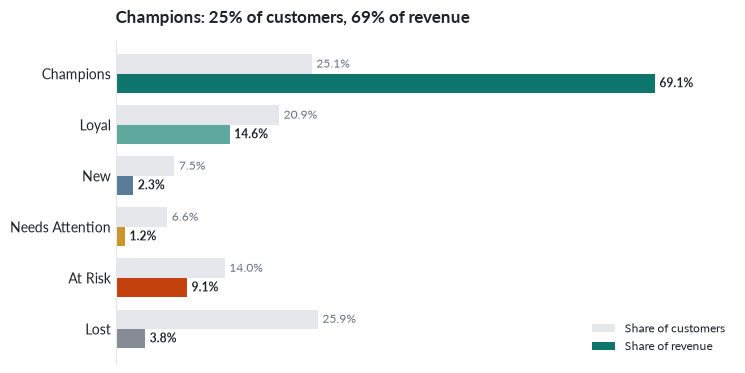

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.2))
y = np.arange(len(SEGMENT_ORDER))[::-1]
h = 0.38
ax.barh(y + h / 2, seg.customer_share_pct, h, color=GRID, label="Share of customers")
ax.barh(y - h / 2, seg.revenue_share_pct, h, color=[SEGMENT_COLOURS[s] for s in SEGMENT_ORDER], label="Share of revenue")
for yi, c, r in zip(y, seg.customer_share_pct, seg.revenue_share_pct):
    ax.text(c + 0.6, yi + h / 2, f"{c:.1f}%", va="center", fontsize=8.5, color=MUTED)
    ax.text(r + 0.6, yi - h / 2, f"{r:.1f}%", va="center", fontsize=8.5, color=INK, fontweight="bold")
ax.set_yticks(y, SEGMENT_ORDER)
ax.set_xlim(0, seg[["customer_share_pct", "revenue_share_pct"]].max().max() * 1.15)
ax.xaxis.set_visible(False)
ax.spines["bottom"].set_visible(False)
ax.tick_params(axis="y", length=0, labelcolor=INK)
ax.set_title(f"Champions: {seg.customer_share_pct['Champions']:.0f}% of customers, {seg.revenue_share_pct['Champions']:.0f}% of revenue")
ax.legend(frameon=False, loc="lower right", fontsize=8.5)
fig.savefig(FIG_DIR / "01_segment_share.png")
plt.show()

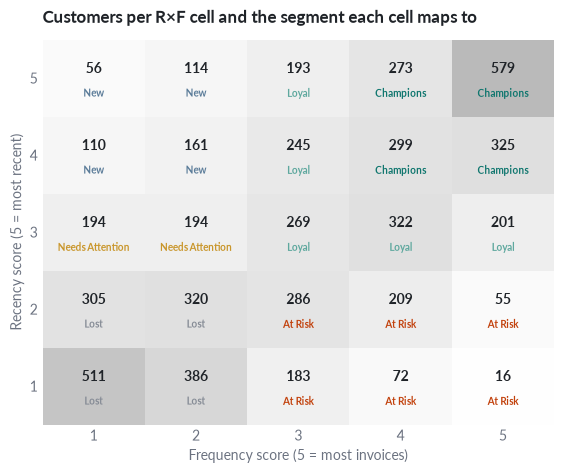

In [12]:
counts = rfm.pivot_table(index="r_score", columns="f_score", values="monetary", aggfunc="size").sort_index(ascending=False)
cell_seg = grid.pivot(index="r", columns="f", values="segment").sort_index(ascending=False)

fig, ax = plt.subplots(figsize=(6.6, 5))
ax.imshow(counts.values, cmap="Greys", vmin=0, vmax=counts.values.max() * 2.6, aspect="auto")
for i in range(5):
    for j in range(5):
        s = cell_seg.iat[i, j]
        ax.text(j, i - 0.12, f"{counts.iat[i, j]:,}", ha="center", va="center", fontsize=10, fontweight="bold", color=INK)
        ax.text(j, i + 0.2, s, ha="center", va="center", fontsize=7.5, color=SEGMENT_COLOURS[s], fontweight="bold")
ax.set_xticks(range(5), counts.columns)
ax.set_yticks(range(5), counts.index)
ax.set_xlabel("Frequency score (5 = most invoices)")
ax.set_ylabel("Recency score (5 = most recent)")
ax.tick_params(length=0)
for side in ax.spines.values():
    side.set_visible(False)
ax.set_title("Customers per R×F cell and the segment each cell maps to")
fig.savefig(FIG_DIR / "02_rf_grid.png")
plt.show()

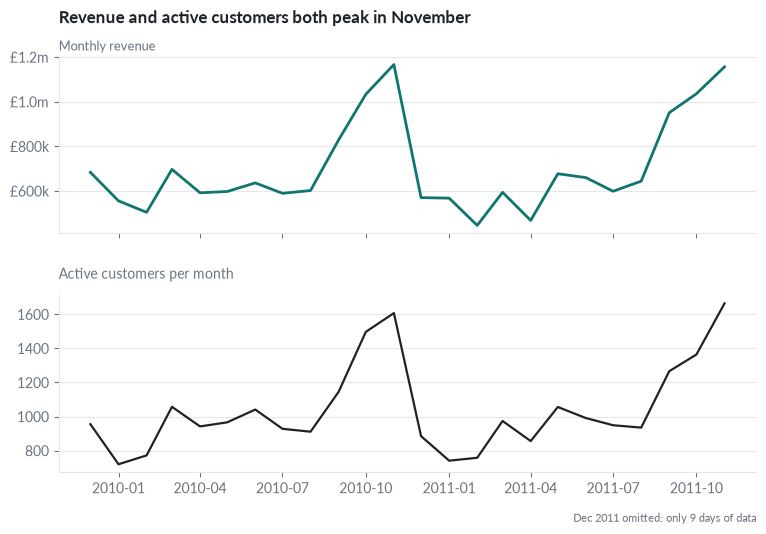

In [13]:
monthly = (tx.assign(month=tx.invoice_date.dt.to_period("M").dt.to_timestamp())
             .groupby("month").agg(revenue=("revenue", "sum"), customers=("customer_id", "nunique")))
partial = monthly.index.max()  # data stops on 9 Dec 2011

full = monthly.drop(partial)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 5.4), sharex=True, gridspec_kw={"hspace": 0.35})
ax1.plot(full.index, full.revenue, color=ACCENT, lw=2)
ax1.yaxis.set_major_formatter(gbp)
ax1.grid(axis="y")
ax1.set_title("Revenue and active customers both peak in November", pad=24)
ax1.text(0, 1.02, "Monthly revenue", transform=ax1.transAxes, fontsize=9, color=MUTED, va="bottom")
ax2.plot(full.index, full.customers, color=INK, lw=1.6)
ax2.grid(axis="y")
ax2.set_title("Active customers per month", fontsize=10, fontweight="normal", color=MUTED)
ax2.text(1, -0.28, "Dec 2011 omitted: only 9 days of data", transform=ax2.transAxes, ha="right", fontsize=8, color=MUTED)
fig.savefig(FIG_DIR / "03_monthly_trend.png")
plt.show()

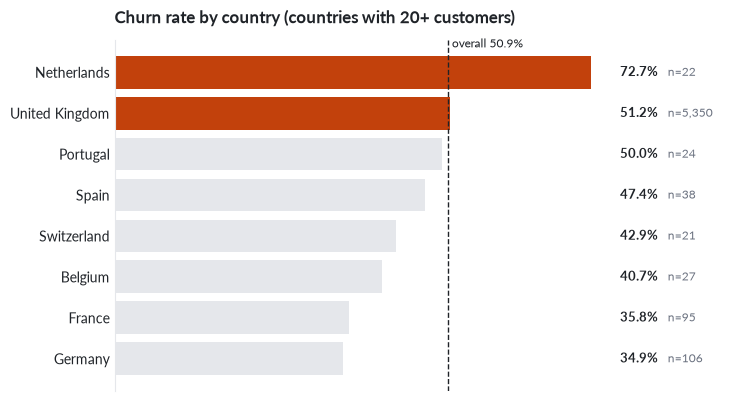

In [14]:
cv = country_view.sort_values("churn_rate_pct")
overall = 100 * rfm.is_churned.mean()
fig, ax = plt.subplots(figsize=(8, 0.42 * len(cv) + 1.2))
colours = [RISK if v > overall else GRID for v in cv.churn_rate_pct]
ax.barh(cv.index, cv.churn_rate_pct, color=colours)
ax.axvline(overall, color=INK, lw=1, ls="--")
ax.text(overall + 0.6, len(cv) - 0.45, f"overall {overall:.1f}%", fontsize=8.5, color=INK, va="bottom", ha="left")
label_x = cv.churn_rate_pct.max() * 1.06
for yi, (v, n) in enumerate(zip(cv.churn_rate_pct, cv.customers)):
    ax.text(label_x, yi, f"{v:.1f}%", va="center", fontsize=9, color=INK, fontweight="bold")
    ax.text(label_x + cv.churn_rate_pct.max() * 0.1, yi, f"n={n:,}", va="center", fontsize=8.5, color=MUTED)
ax.set_xlim(0, cv.churn_rate_pct.max() * 1.3)
ax.xaxis.set_visible(False)
ax.spines["bottom"].set_visible(False)
ax.tick_params(axis="y", length=0, labelcolor=INK)
ax.set_title("Churn rate by country (countries with 20+ customers)")
fig.savefig(FIG_DIR / "04_churn_by_country.png")
plt.show()

## 9. Write results to PostgreSQL
- `customer_rfm` and `segment_rules` are written with `to_sql`.
- `analysis_ready` is built inside Postgres by joining `retail_clean` to `customer_rfm`, which avoids sending 779k rows back through Python. It adds calendar columns for the Power BI slicers.

In [15]:
out = rfm.reset_index()[[
    "customer_id", "country", "first_purchase", "last_purchase", "recency_days", "frequency", "monetary",
    "r_score", "f_score", "m_score", "rfm_score", "segment", "segment_order", "is_churned", "churn_status",
]]
out["monetary"] = out.monetary.round(2)
out.to_sql("customer_rfm", engine, if_exists="replace", index=False, chunksize=5000)
segment_rules.to_sql("segment_rules", engine, if_exists="replace", index=False)

with engine.begin() as con:
    con.execute(text("ALTER TABLE customer_rfm ADD PRIMARY KEY (customer_id)"))
    con.execute(text("DROP TABLE IF EXISTS analysis_ready"))
    con.execute(text('''
        CREATE TABLE analysis_ready AS
        SELECT t.invoice,
               t.stock_code,
               t.description,
               t.quantity,
               t.price,
               t.revenue,
               t.invoice_date,
               t.invoice_date::DATE                       AS invoice_day,
               EXTRACT(YEAR FROM t.invoice_date)::INT     AS year,
               'Q' || EXTRACT(QUARTER FROM t.invoice_date) AS quarter,
               TO_CHAR(t.invoice_date, 'YYYY-"Q"Q')       AS year_quarter,
               EXTRACT(MONTH FROM t.invoice_date)::INT    AS month_num,
               TO_CHAR(t.invoice_date, 'Mon')             AS month_name,
               TO_CHAR(t.invoice_date, 'YYYY-MM')         AS year_month,
               t.country,
               t.customer_id,
               c.country                                  AS customer_country,
               c.segment,
               c.segment_order,
               c.r_score,
               c.f_score,
               c.m_score,
               c.rfm_score,
               c.recency_days,
               c.frequency,
               c.monetary,
               c.is_churned,
               c.churn_status
        FROM retail_clean t
        JOIN customer_rfm c USING (customer_id)
    '''))
    con.execute(text("CREATE INDEX ON analysis_ready (customer_id)"))

check = pd.read_sql('''
    SELECT (SELECT COUNT(*) FROM customer_rfm)                     AS customer_rfm_rows,
           (SELECT COUNT(*) FROM analysis_ready)                   AS analysis_ready_rows,
           (SELECT COUNT(*) FROM retail_clean)                     AS retail_clean_rows,
           (SELECT ROUND(SUM(revenue), 2) FROM analysis_ready)     AS analysis_ready_revenue,
           (SELECT ROUND(SUM(revenue), 2) FROM retail_clean)       AS retail_clean_revenue,
           (SELECT COUNT(*) FROM analysis_ready WHERE segment IS NULL) AS rows_without_segment
''', engine)
assert check.customer_rfm_rows[0] == len(rfm)
assert check.analysis_ready_rows[0] == check.retail_clean_rows[0]
assert check.rows_without_segment[0] == 0
assert check.analysis_ready_revenue[0] == check.retail_clean_revenue[0]
check.T

,0
customer_rfm_rows,5878.00
analysis_ready_rows,779425.00
retail_clean_rows,779425.00
analysis_ready_revenue,17374804.27
retail_clean_revenue,17374804.27
rows_without_segment,0.00
